In [1]:
#
# Cell 1: import libraries
#

import numpy as np
import pandas as pd
import pickle
import random

In [3]:
#
# Cell 2:Path for input data and definition of sampling rate
# Note: not used for this module
#

#path = 'C:/Users/Buchh/OneDrive/Leuphana_Data_Science/Masterarbeit/ECG/Python/Daten_einlesen/test_data/'
path = 'D:/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'
sampling_rate=100


In [5]:
#
# Cell 3: Specify the directory name for loading of data
#

from pathlib import Path

directory_path = Path("D:/ECG/X_zero")

## Run cell 4, if you want to augment the original X-data

In [9]:
#
# Cell 4:Loading stored raw data, if available. 
#

X = np.load(directory_path/'X_float32.npy', mmap_mode='r')
#Y = pd.read_pickle('Y_data.pkl')


## Run the following cells if you want to shorten the length of the ECG 

In [11]:
#
# Cell 5: specify new length of ECGS 
#

new_length = 200
X_short = X[:,0:new_length,:]

number_of_ECGs, new_length_of_EGC, number_of_leads =X_short.shape
print('Number of ECGs: ', number_of_ECGs)
print('Length of ECG: ', new_length_of_EGC)
print('Number of leads: ', number_of_leads)

Number of ECGs:  21799
Length of ECG:  200
Number of leads:  12


In [15]:
#
# Cell 6: Select lead (0 to 11)
#

number_of_lead = 0
X_short_one_lead = X_short[:,:,0]
#
number_of_ECGs, new_length_of_EGC =X_short_one_lead.shape
print('Number of ECGs: ', number_of_ECGs)
print('Length of ECG: ', new_length_of_EGC)
#print('Number of leads: ', number_of_leads)


Number of ECGs:  21799
Length of ECG:  200


In [19]:
#
# Cell 7: 
#


max_element_row = np.max(X_short_one_lead, 1)
min_element_row = np.amin(X_short_one_lead, 1)

print('maximum elements in the rows of the array is:', 
      max_element_row)
print('minimum elements in the rows of the array is:',
      min_element_row)

maximum elements in the rows of the array is: [0.521 0.526 0.784 ... 0.701 0.611 0.877]
minimum elements in the rows of the array is: [-0.195 -0.265 -0.119 ... -0.125 -0.089 -0.127]


In [21]:
max_max_element_row = np.max(max_element_row)
min_max_element_row = np.amin(max_element_row)

print('maximum element in the row is:', 
      max_max_element_row)
print('minimum element in the row is:',
      min_max_element_row)

maximum element in the row is: 3.339
minimum element in the row is: -4.99


In [25]:
mean_max_element_row = np.mean(max_element_row)

print('mean element in the row is:', 
      mean_max_element_row)

mean element in the row is: 0.75424135


In [23]:
max_min_element_row = np.max(min_element_row)
min_min_element_row = np.amin(min_element_row)

print('maximum element in the row is:', 
      max_min_element_row)
print('minimum element in the row is:',
      min_min_element_row)

maximum element in the row is: 0.618
minimum element in the row is: -6.985


In [27]:
mean_min_element_row = np.mean(min_element_row)

print('mean element in the row is:', 
      mean_min_element_row)

mean element in the row is: -0.21211505


In [90]:
#
# Cell 5c: specify new length of ECGS 
#

length_of_EGC = new_length_of_EGC
X=X_short 

## End of cells for shortended ECGs 

# The following cells are for visualization of the shifted data only 

In [ ]:
#
#import pylab as pl
#

from biosppy import storage
from biosppy.signals import ecg

In [21]:
#
# Cell 10: assign "X_shifted" EGG data of one ECG to input "signal" for ecg-function
# This is for diagnostic purpose.

signal = X_shifted[3,:,0]

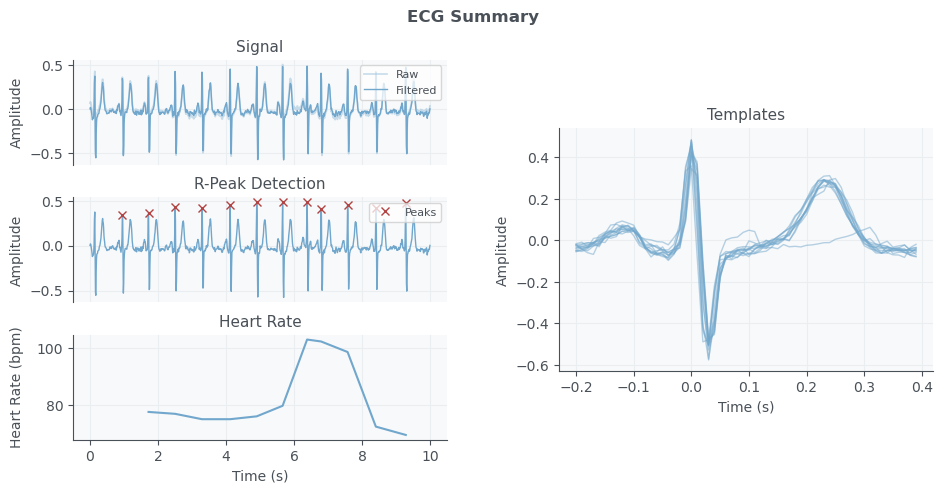

array([ 95, 172, 250, 329, 412, 490, 566, 638, 679, 757, 840, 928])

In [23]:
#
# Cell 11: process it and plot
#

out = ecg.ecg(signal=signal, sampling_rate=100., show=True)[2]
out